# SDI201 Lab: Network Threat Detection and Early Warning with ML and DL

**Student Name:** Maftuna Sharabbaeva  
**Student ID:** 380261200262  
**Group:** 210-26 Slr

## Dataset
TON_IoT Network Dataset - `train_test_network.csv`

## Tasks
1. Data exploration and leakage
2. Preprocessing and Random Forest baseline
3. Machine learning vs deep learning
4. Unknown attacks and autoencoder
5. Early-warning layer and false alarms

In [3]:
# ============================================
# SETUP
# ============================================

%pip install -q pandas scikit-learn xgboost tensorflow matplotlib seaborn

import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import xgboost
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries loaded successfully!")
print("=" * 60)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgboost.__version__)
print("tensorflow:", tf.__version__)
print("numpy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)

Libraries loaded successfully!
pandas: 2.2.3
scikit-learn: 1.6.1
xgboost: 3.4.1
tensorflow: 2.21.0
numpy: 2.1.3
matplotlib: 3.10.0


In [4]:
# ============================================
# UPLOAD DATASET
# ============================================

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print("-", filename)

Saving train_test_network.csv to train_test_network.csv

Uploaded files:
- train_test_network.csv


In [5]:
# ============================================
# LOAD DATASET
# ============================================

DATA_PATH = "/content/train_test_network.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("=" * 60)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Rows: 211043
Columns: 44

Column names:
['src_ip', 'src_port', 'dst_ip', 'dst_port', 'proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_query', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice', 'label', 'type']

First 5 rows:


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


# Task 1: Data Exploration and Leakage

The goal of Task 1 is to understand the network connection data and demonstrate why identifier columns such as IP addresses can cause data leakage.

In [6]:
# ============================================
# TASK 1.1: CLASS COUNTS
# ============================================

print("LABEL DISTRIBUTION")
print("=" * 60)

label_counts = df["label"].value_counts().sort_index()

label_table = pd.DataFrame({
    "Label": ["Normal", "Attack"],
    "Count": [
        label_counts.get(0, 0),
        label_counts.get(1, 0)
    ]
})

label_table["Percentage"] = (
    label_table["Count"] / len(df) * 100
)

display(label_table)

print("\nTYPE DISTRIBUTION")
print("=" * 60)

type_counts = df["type"].value_counts()

type_table = (
    type_counts
    .rename_axis("Attack Type")
    .reset_index(name="Count")
)

type_table["Percentage"] = (
    type_table["Count"] / len(df) * 100
)

display(type_table)

LABEL DISTRIBUTION


,Label,Count,Percentage
0,Normal,50000,23.691854
1,Attack,161043,76.308146



TYPE DISTRIBUTION


,Attack Type,Count,Percentage
0,normal,50000,23.691854
1,backdoor,20000,9.476742
2,ddos,20000,9.476742
3,dos,20000,9.476742
4,injection,20000,9.476742
5,password,20000,9.476742
6,scanning,20000,9.476742
7,ransomware,20000,9.476742
8,xss,20000,9.476742
9,mitm,1043,0.494212


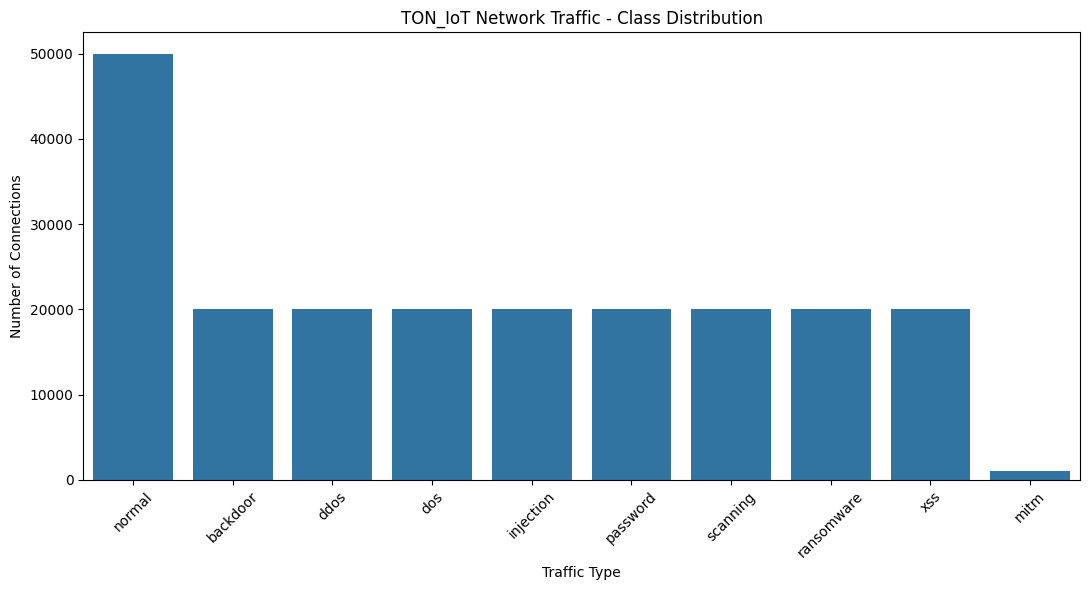

In [7]:
# ============================================
# TASK 1.1: TYPE BAR CHART
# ============================================

plt.figure(figsize=(11, 6))

sns.barplot(
    data=type_table,
    x="Attack Type",
    y="Count"
)

plt.title("TON_IoT Network Traffic - Class Distribution")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Connections")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# ============================================
# TASK 1.1: ATTACK SHARE
# ============================================

attack_percentage = (
    (df["label"] == 1).mean() * 100
)

smallest_class = type_counts.idxmin()
smallest_count = type_counts.min()

print(f"Total rows: {len(df):,}")
print(f"Attack rows: {(df['label'] == 1).sum():,}")
print(f"Normal rows: {(df['label'] == 0).sum():,}")
print(f"Attack share: {attack_percentage:.2f}%")
print(
    f"Smallest class: {smallest_class} "
    f"({smallest_count:,} rows)"
)

Total rows: 211,043
Attack rows: 161,043
Normal rows: 50,000
Attack share: 76.31%
Smallest class: mitm (1,043 rows)


In [9]:
# ============================================
# TASK 1.2: SCANNING VS NORMAL
# ============================================

comparison_columns = [
    "type",
    "dst_port",
    "src_pkts",
    "dst_pkts",
    "duration",
    "conn_state"
]

scanning_rows = df[df["type"] == "scanning"].head(2)

normal_rows = df[df["type"] == "normal"].head(2)

comparison = pd.concat(
    [scanning_rows, normal_rows]
)[comparison_columns]

display(comparison)

,type,dst_port,src_pkts,dst_pkts,duration,conn_state
171043,scanning,2046,1,0,0.0,S0
171044,scanning,7435,1,0,0.0,S0
81043,normal,15600,1,0,0.0,S0
81044,normal,51782,0,0,0.0,OTH


### Human Rule for Scanning

**If a connection repeatedly targets destination ports while exchanging very few packets and little or no data, then it is probably scanning.**

This pattern is consistent with reconnaissance: the attacker probes different services or ports to discover which services are available on a host before attempting a more targeted attack.

In [10]:
# ============================================
# TASK 1.3: IP-ONLY LEAKAGE EXPERIMENT
# ============================================

from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

# Use ONLY source and destination IP addresses
X_ip = df[["src_ip", "dst_ip"]].astype(str)

# Encode source IP
src_ip_encoder = LabelEncoder()
X_ip_encoded = X_ip.copy()

X_ip_encoded["src_ip"] = (
    src_ip_encoder.fit_transform(X_ip_encoded["src_ip"])
)

# Encode destination IP
dst_ip_encoder = LabelEncoder()

X_ip_encoded["dst_ip"] = (
    dst_ip_encoder.fit_transform(X_ip_encoded["dst_ip"])
)

# Target = 10-class traffic type
type_encoder_ip = LabelEncoder()

y_ip = type_encoder_ip.fit_transform(
    df["type"].astype(str)
)

# Stratified split
X_ip_train, X_ip_test, y_ip_train, y_ip_test = train_test_split(
    X_ip_encoded,
    y_ip,
    test_size=0.20,
    random_state=42,
    stratify=y_ip
)

# Random Forest using only IPs
ip_rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

print("Training IP-only Random Forest...")
start_time = time.time()

ip_rf_model.fit(
    X_ip_train,
    y_ip_train
)

ip_training_time = time.time() - start_time

# Predict
y_ip_pred = ip_rf_model.predict(X_ip_test)

ip_accuracy = accuracy_score(
    y_ip_test,
    y_ip_pred
)

print("\n" + "=" * 60)
print("IP-ONLY LEAKAGE EXPERIMENT")
print("=" * 60)
print(f"Accuracy: {ip_accuracy:.4f}")
print(f"Accuracy: {ip_accuracy * 100:.2f}%")
print(f"Training time: {ip_training_time:.2f} seconds")

Training IP-only Random Forest...

IP-ONLY LEAKAGE EXPERIMENT
Accuracy: 0.8203
Accuracy: 82.03%
Training time: 18.18 seconds


### Task 1 Interpretation: IP Leakage

The IP-only Random Forest achieved a test accuracy of **82.03%**using only src_ip and dst_ip, showing that IP addresses contain strong network-specific information associated with the traffic classes. This is a form of data leakage because the model can memorize relationships between particular hosts and attack types rather than learning general characteristics of network traffic. On a different network, the IP addresses and host relationships would likely change, so this model would not generalize reliably. Therefore, src_ip and dst_ip should be removed from the predictive feature set, along with other identifier or free-text fields such as src_port, dns_query, ssl_subject, ssl_issuer, http_uri, http_user_agent, and weird_addl.

# Task 2: Preprocessing and Random Forest Baseline

The goal of this task is to create a leakage-free feature matrix and train a reproducible Random Forest baseline for the 10-class `type` target.

In [11]:
# ============================================
# TASK 2.1: REMOVE LEAKAGE / IDENTIFIER COLUMNS
# ============================================

# Columns that must not be used as model features
drop_columns = [
    "src_ip",
    "dst_ip",
    "src_port",
    "dns_query",
    "ssl_subject",
    "ssl_issuer",
    "http_uri",
    "http_user_agent",
    "weird_addl"
]

# Keep original df unchanged
task2_df = df.copy()

# Separate target before dropping columns
y = task2_df["type"].copy()

# Remove target columns and leakage columns
X_raw = task2_df.drop(
    columns=["label", "type"] + drop_columns,
    errors="ignore"
).copy()

print("Original dataset shape:", df.shape)
print("Feature matrix before preprocessing:", X_raw.shape)

print("\nDropped columns:")
for col in drop_columns:
    print("-", col)

print("\nRemaining feature columns:")
print(X_raw.columns.tolist())

Original dataset shape: (211043, 44)
Feature matrix before preprocessing: (211043, 33)

Dropped columns:
- src_ip
- dst_ip
- src_port
- dns_query
- ssl_subject
- ssl_issuer
- http_uri
- http_user_agent
- weird_addl

Remaining feature columns:
['dst_port', 'proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'http_trans_depth', 'http_method', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_notice']


In [12]:
# ============================================
# TASK 2.2: CLEAN DATA AND CREATE MAIN SPLIT
# ============================================

# Make a fresh copy
X_clean = X_raw.copy()

# Replace "-" with missing values
X_clean = X_clean.replace("-", np.nan)

# Target: 10-class traffic/attack type
y_main = y.astype(str)

print("Before type conversion:")
print(X_clean.dtypes.value_counts())

# Try to convert object columns that are actually numeric
for col in X_clean.columns:
    if X_clean[col].dtype == "object":
        converted = pd.to_numeric(
            X_clean[col],
            errors="coerce"
        )

        # If almost all non-missing values are numeric,
        # treat the column as numeric
        original_non_missing = X_clean[col].notna().sum()

        if original_non_missing > 0:
            numeric_ratio = (
                converted.notna().sum() / original_non_missing
            )

            if numeric_ratio >= 0.95:
                X_clean[col] = converted

print("\nAfter type conversion:")
print(X_clean.dtypes.value_counts())

# --------------------------------------------
# ONE OFFICIAL STRATIFIED 80/20 SPLIT
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_main,
    test_size=0.20,
    random_state=42,
    stratify=y_main
)

print("\n" + "=" * 60)
print("MAIN STRATIFIED 80/20 SPLIT")
print("=" * 60)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Before type conversion:
object     18
int64      14
float64     1
Name: count, dtype: int64

After type conversion:
object     16
int64      14
float64     3
Name: count, dtype: int64

MAIN STRATIFIED 80/20 SPLIT
Training: (168834, 33)
Testing : (42209, 33)

Training class distribution:
type
normal        40000
password      16000
backdoor      16000
xss           16000
ransomware    16000
ddos          16000
scanning      16000
dos           16000
injection     16000
mitm            834
Name: count, dtype: int64

Testing class distribution:
type
normal        10000
backdoor       4000
password       4000
scanning       4000
ransomware     4000
injection      4000
xss            4000
dos            4000
ddos           4000
mitm            209
Name: count, dtype: int64


In [13]:
# ============================================
# TASK 2.3: NUMERIC AND CATEGORICAL FEATURES
# ============================================

numeric_features = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=[np.number]
).columns.tolist()

print("Number of numerical features:",
      len(numeric_features))

print("Number of categorical features:",
      len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 17
Number of categorical features: 16

Numerical features:
['dst_port', 'duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'http_trans_depth', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code']

Categorical features:
['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'http_method', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_notice']


In [14]:
# ============================================
# TASK 2.4: HANDLE MISSING VALUES + LOG1P
# ============================================

# Work on copies
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

# --------------------------------------------
# Numeric missing values
# --------------------------------------------

X_train_processed[numeric_features] = (
    X_train_processed[numeric_features].fillna(0)
)

X_test_processed[numeric_features] = (
    X_test_processed[numeric_features].fillna(0)
)

# --------------------------------------------
# Categorical missing values
# --------------------------------------------

X_train_processed[categorical_features] = (
    X_train_processed[categorical_features]
    .fillna("missing")
    .astype(str)
)

X_test_processed[categorical_features] = (
    X_test_processed[categorical_features]
    .fillna("missing")
    .astype(str)
)

# --------------------------------------------
# log1p heavy-tailed non-negative features
# --------------------------------------------

log_features = [
    col for col in [
        "duration",
        "src_bytes",
        "dst_bytes",
        "missed_bytes",
        "src_pkts",
        "src_ip_bytes",
        "dst_pkts",
        "dst_ip_bytes",
        "dns_qclass",
        "dns_qtype",
        "dns_rcode",
        "http_request_body_len",
        "http_response_body_len"
    ]
    if col in numeric_features
]

print("Features receiving log1p transformation:")
print(log_features)

# Apply log1p
for col in log_features:
    # Clip negative values defensively
    X_train_processed[col] = np.log1p(
        X_train_processed[col].clip(lower=0)
    )

    X_test_processed[col] = np.log1p(
        X_test_processed[col].clip(lower=0)
    )

print("\nMissing values remaining in training:",
      X_train_processed.isnull().sum().sum())

print("Missing values remaining in testing:",
      X_test_processed.isnull().sum().sum())

Features receiving log1p transformation:
['duration', 'src_bytes', 'dst_bytes', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'http_request_body_len', 'http_response_body_len']

Missing values remaining in training: 0
Missing values remaining in testing: 0


In [15]:
# ============================================
# TASK 2.5: ENCODE AND SCALE
# ============================================

# StandardScaler is fitted ONLY on training data
scaler = StandardScaler()

X_train_numeric = scaler.fit_transform(
    X_train_processed[numeric_features]
)

X_test_numeric = scaler.transform(
    X_test_processed[numeric_features]
)

# OneHotEncoder is fitted ONLY on training data
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_categorical = encoder.fit_transform(
    X_train_processed[categorical_features]
)

X_test_categorical = encoder.transform(
    X_test_processed[categorical_features]
)

# Combine numerical + categorical features
X_train_final = np.hstack([
    X_train_numeric,
    X_train_categorical
])

X_test_final = np.hstack([
    X_test_numeric,
    X_test_categorical
])

print("Final training matrix:", X_train_final.shape)
print("Final testing matrix :", X_test_final.shape)

print(
    "\nFinal number of feature columns:",
    X_train_final.shape[1]
)

Final training matrix: (168834, 99)
Final testing matrix : (42209, 99)

Final number of feature columns: 99


In [16]:
# ============================================
# TASK 2.6: RANDOM FOREST BASELINE
# ============================================

print("Training Random Forest...")
print("Please wait...")

rf_start = time.time()

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_final,
    y_train
)

rf_training_time = time.time() - rf_start

print("\nRandom Forest training completed!")
print(f"Training time: {rf_training_time:.2f} seconds")

Training Random Forest...
Please wait...

Random Forest training completed!
Training time: 36.38 seconds


In [17]:
# ============================================
# TASK 2.7: RANDOM FOREST EVALUATION
# ============================================

# Predictions
y_pred_rf = rf_model.predict(X_test_final)

# Basic metrics
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_macro_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="macro"
)

rf_weighted_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

print("=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)

print(f"Accuracy    : {rf_accuracy:.4f}")
print(f"Macro-F1    : {rf_macro_f1:.4f}")
print(f"Weighted-F1 : {rf_weighted_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=4
    )
)

RANDOM FOREST RESULTS
Accuracy    : 0.9872
Macro-F1    : 0.9635
Weighted-F1 : 0.9872

Classification Report:
              precision    recall  f1-score   support

    backdoor     0.9995    0.9992    0.9994      4000
        ddos     0.9827    0.9795    0.9811      4000
         dos     0.9852    0.9818    0.9835      4000
   injection     0.9683    0.9685    0.9684      4000
        mitm     0.7330    0.7751    0.7535       209
      normal     0.9979    0.9967    0.9973     10000
    password     0.9918    0.9935    0.9926      4000
  ransomware     0.9997    0.9990    0.9994      4000
    scanning     0.9870    0.9872    0.9871      4000
         xss     0.9704    0.9758    0.9731      4000

    accuracy                         0.9872     42209
   macro avg     0.9616    0.9656    0.9635     42209
weighted avg     0.9872    0.9872    0.9872     42209



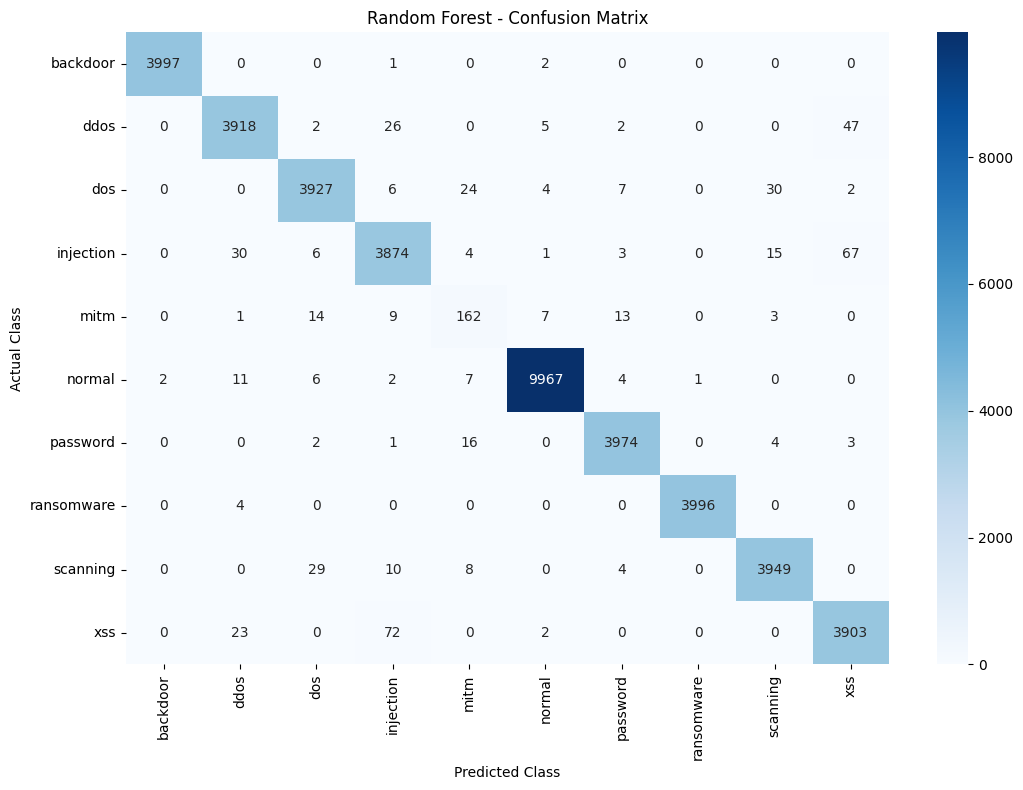

In [18]:
# ============================================
# TASK 2.8: CONFUSION MATRIX
# ============================================

class_labels = sorted(y_test.unique())

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=class_labels
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [19]:
# ============================================
# TASK 2.9: BINARY ATTACK METRICS
# ============================================

# Convert 10-class predictions into binary:
# 0 = Normal
# 1 = Attack

actual_attack_binary = (
    y_test != "normal"
).astype(int)

predicted_attack_binary = (
    y_pred_rf != "normal"
).astype(int)

# Confusion matrix for Normal vs Attack
binary_cm = confusion_matrix(
    actual_attack_binary,
    predicted_attack_binary,
    labels=[0, 1]
)

tn, fp, fn, tp = binary_cm.ravel()

binary_attack_recall = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

false_positive_rate = (
    fp / (fp + tn)
    if (fp + tn) > 0
    else 0
)

print("=" * 60)
print("BINARY ATTACK DETECTION METRICS")
print("=" * 60)

print(f"True Negatives : {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Positives : {tp:,}")

print(f"\nBinary Attack Recall: {binary_attack_recall:.4f}")
print(f"False-Positive Rate : {false_positive_rate:.6f}")
print(f"False-Positive Rate : {false_positive_rate * 100:.4f}%")

BINARY ATTACK DETECTION METRICS
True Negatives : 9,967
False Positives: 33
False Negatives: 21
True Positives : 32,188

Binary Attack Recall: 0.9993
False-Positive Rate : 0.003300
False-Positive Rate : 0.3300%


In [20]:
# ============================================
# TASK 2.10: TOP 15 FEATURE IMPORTANCES
# ============================================

# Get one-hot encoded categorical feature names
encoded_categorical_names = (
    encoder.get_feature_names_out(categorical_features)
)

# Combine numerical + categorical names
final_feature_names = (
    numeric_features +
    encoded_categorical_names.tolist()
)

print("Number of feature names:", len(final_feature_names))
print("Number of model features:", len(rf_model.feature_importances_))

# Create importance table
importance_df = pd.DataFrame({
    "Feature": final_feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = (
    importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

top15 = importance_df.head(15)

print("\nTop 15 features:")
display(top15)

Number of feature names: 99
Number of model features: 99

Top 15 features:


,Feature,Importance
0,src_ip_bytes,0.179298
1,dst_port,0.132858
2,duration,0.106587
3,dst_ip_bytes,0.067895
4,src_pkts,0.059459
5,src_bytes,0.055092
6,dst_pkts,0.044461
7,dst_bytes,0.037834
8,conn_state_REJ,0.035387
9,conn_state_S0,0.034665


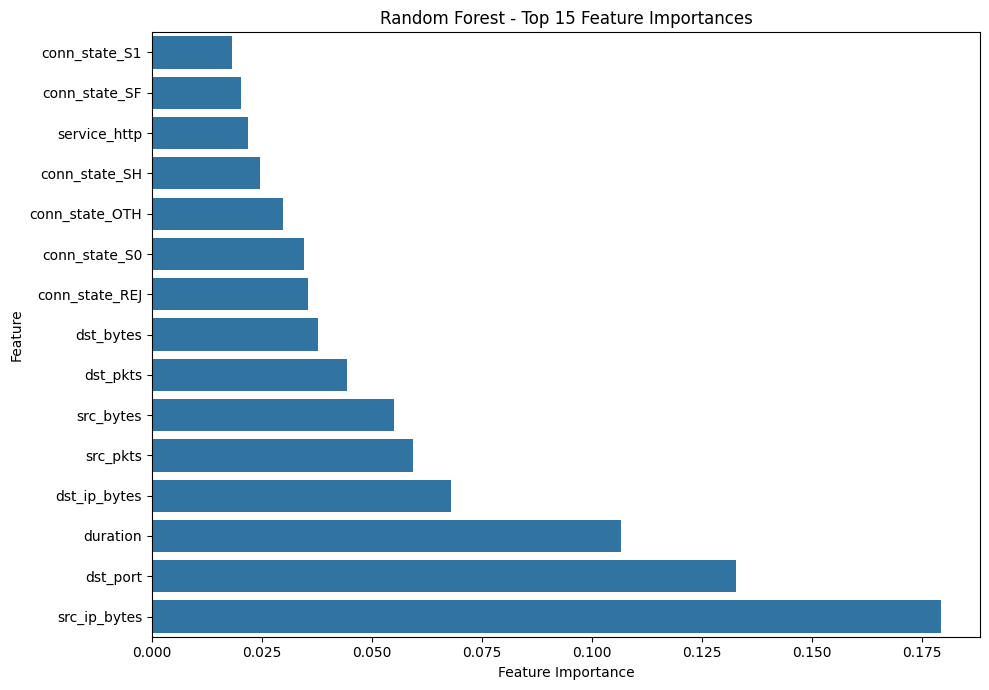

In [21]:
# ============================================
# TOP 15 FEATURE IMPORTANCE PLOT
# ============================================

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top15.sort_values("Importance"),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Task 2 Discussion

The Random Forest achieved an accuracy of 98.72% and a macro-F1 score of 0.9635. Macro-F1 is particularly important because it gives equal weight to each traffic class, whereas accuracy can be dominated by the larger classes. This is important in this dataset because the MITM class contains only 209 test samples and has a much lower F1 score of 0.7535 than the other classes. The confusion matrix shows that MITM is the most difficult class, with errors mainly involving DOS, password, injection and DDOS traffic. Another noticeable source of confusion is between injection and XSS, which may occur because both attacks can produce similar network-level characteristics. The model's binary attack recall is 99.93%, while the false-positive rate among normal flows is 0.33%, indicating strong attack detection with relatively few false alarms.The feature-importance analysis shows that src_ip_bytes, dst_port, and duration are among the most influential features for the Random Forest model. These features represent network traffic characteristics rather than direct host identifiers, supporting the use of behavioural features after removing leakage-prone columns.

# Task 3: Machine Learning vs Deep Learning

Random Forest, XGBoost and a Multi-Layer Perceptron (MLP) are compared using the same cleaned feature matrix and the same stratified 80/20 train/test split.

In [22]:
# ============================================
# TASK 3.1: XGBOOST
# ============================================

from xgboost import XGBClassifier

print("Training XGBoost...")
print("Please wait...")

xgb_start = time.time()

# Encode target labels as integers for XGBoost
xgb_label_encoder = LabelEncoder()

y_train_xgb = xgb_label_encoder.fit_transform(y_train)
y_test_xgb = xgb_label_encoder.transform(y_test)

# Calculate balanced sample weights
class_counts = np.bincount(y_train_xgb)

class_weights = {
    i: len(y_train_xgb) / (len(class_counts) * count)
    for i, count in enumerate(class_counts)
}

sample_weights = np.array([
    class_weights[label]
    for label in y_train_xgb
])

xgb_model = XGBClassifier(
    n_estimators=400,
    max_depth=8,
    learning_rate=0.1,
    tree_method="hist",
    objective="multi:softprob",
    num_class=len(xgb_label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_final,
    y_train_xgb,
    sample_weight=sample_weights
)

xgb_training_time = time.time() - xgb_start

print("\nXGBoost training completed!")
print(f"Training time: {xgb_training_time:.2f} seconds")

Training XGBoost...
Please wait...

XGBoost training completed!
Training time: 188.87 seconds


In [23]:
# ============================================
# TASK 3.2: XGBOOST EVALUATION
# ============================================

# Predict class probabilities and classes
xgb_pred_encoded = xgb_model.predict(X_test_final)

# Convert integer predictions back to original class names
y_pred_xgb = xgb_label_encoder.inverse_transform(
    xgb_pred_encoded.astype(int)
)

# Metrics
xgb_accuracy = accuracy_score(
    y_test,
    y_pred_xgb
)

xgb_macro_f1 = f1_score(
    y_test,
    y_pred_xgb,
    average="macro"
)

xgb_weighted_f1 = f1_score(
    y_test,
    y_pred_xgb,
    average="weighted"
)

print("=" * 60)
print("XGBOOST RESULTS")
print("=" * 60)

print(f"Accuracy    : {xgb_accuracy:.4f}")
print(f"Macro-F1    : {xgb_macro_f1:.4f}")
print(f"Weighted-F1 : {xgb_weighted_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_xgb,
        digits=4
    )
)

XGBOOST RESULTS
Accuracy    : 0.9888
Macro-F1    : 0.9644
Weighted-F1 : 0.9891

Classification Report:
              precision    recall  f1-score   support

    backdoor     0.9997    0.9995    0.9996      4000
        ddos     0.9879    0.9822    0.9851      4000
         dos     0.9912    0.9805    0.9858      4000
   injection     0.9857    0.9665    0.9760      4000
        mitm     0.6379    0.8852    0.7415       209
      normal     0.9983    0.9962    0.9972     10000
    password     0.9952    0.9908    0.9930      4000
  ransomware     0.9988    0.9990    0.9989      4000
    scanning     0.9841    0.9910    0.9875      4000
         xss     0.9703    0.9882    0.9792      4000

    accuracy                         0.9888     42209
   macro avg     0.9549    0.9779    0.9644     42209
weighted avg     0.9896    0.9888    0.9891     42209



In [24]:
# ============================================
# TASK 3.2: XGBOOST BINARY ATTACK METRICS
# ============================================

actual_attack_binary_xgb = (
    y_test != "normal"
).astype(int)

predicted_attack_binary_xgb = (
    y_pred_xgb != "normal"
).astype(int)

binary_cm_xgb = confusion_matrix(
    actual_attack_binary_xgb,
    predicted_attack_binary_xgb,
    labels=[0, 1]
)

tn_xgb, fp_xgb, fn_xgb, tp_xgb = binary_cm_xgb.ravel()

xgb_recall = (
    tp_xgb / (tp_xgb + fn_xgb)
    if (tp_xgb + fn_xgb) > 0
    else 0
)

xgb_fpr = (
    fp_xgb / (fp_xgb + tn_xgb)
    if (fp_xgb + tn_xgb) > 0
    else 0
)

print("=" * 60)
print("XGBOOST BINARY ATTACK METRICS")
print("=" * 60)

print(f"Binary Attack Recall: {xgb_recall:.4f}")
print(f"False-Positive Rate : {xgb_fpr:.6f}")
print(f"False-Positive Rate : {xgb_fpr * 100:.4f}%")

XGBOOST BINARY ATTACK METRICS
Binary Attack Recall: 0.9995
False-Positive Rate : 0.003800
False-Positive Rate : 0.3800%


In [25]:
# ============================================
# TASK 3.3: MULTI-LAYER PERCEPTRON (MLP)
# ============================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping

print("Preparing MLP...")
print("TensorFlow version:", tf.__version__)

# ------------------------------------------------
# Encode target classes as integers
# ------------------------------------------------

mlp_label_encoder = LabelEncoder()

y_train_mlp = mlp_label_encoder.fit_transform(y_train)
y_test_mlp = mlp_label_encoder.transform(y_test)

num_classes = len(mlp_label_encoder.classes_)

print("Number of classes:", num_classes)
print("Classes:", mlp_label_encoder.classes_)

# ------------------------------------------------
# Calculate balanced class weights
# ------------------------------------------------

mlp_class_weights = {}

class_counts_mlp = np.bincount(y_train_mlp)

for class_index, count in enumerate(class_counts_mlp):
    mlp_class_weights[class_index] = (
        len(y_train_mlp) /
        (num_classes * count)
    )

print("\nClass weights:")
print(mlp_class_weights)

# ------------------------------------------------
# Build MLP
# ------------------------------------------------

mlp_model = Sequential([

    # Input layer + hidden layer 1
    Dense(
        128,
        activation="relu",
        input_shape=(X_train_final.shape[1],)
    ),
    BatchNormalization(),
    Dropout(0.30),

    # Hidden layer 2
    Dense(
        64,
        activation="relu"
    ),
    BatchNormalization(),
    Dropout(0.30),

    # Output layer
    Dense(
        num_classes,
        activation="softmax"
    )
])

# ------------------------------------------------
# Compile
# ------------------------------------------------

mlp_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nMLP architecture:")
mlp_model.summary()

# ------------------------------------------------
# Early stopping
# ------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# ------------------------------------------------
# Train
# ------------------------------------------------

print("\nTraining MLP...")
print("Please wait...")

mlp_start = time.time()

mlp_history = mlp_model.fit(
    X_train_final,
    y_train_mlp,
    validation_split=0.10,
    epochs=30,
    batch_size=512,
    class_weight=mlp_class_weights,
    callbacks=[early_stopping],
    verbose=1
)

mlp_training_time = time.time() - mlp_start

print("\nMLP training completed!")
print(f"Training time: {mlp_training_time:.2f} seconds")

Preparing MLP...
TensorFlow version: 2.21.0
Number of classes: 10
Classes: ['backdoor' 'ddos' 'dos' 'injection' 'mitm' 'normal' 'password'
 'ransomware' 'scanning' 'xss']

Class weights:
{0: np.float64(1.0552125), 1: np.float64(1.0552125), 2: np.float64(1.0552125), 3: np.float64(1.0552125), 4: np.float64(20.24388489208633), 5: np.float64(0.422085), 6: np.float64(1.0552125), 7: np.float64(1.0552125), 8: np.float64(1.0552125), 9: np.float64(1.0552125)}

MLP architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,474 (87.79 KB)

 Trainable params: 22,090 (86.29 KB)

 Non-trainable params: 384 (1.50 KB)


Training MLP...
Please wait...
Epoch 1/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7214 - loss: 0.8806 - val_accuracy: 0.8294 - val_loss: 0.6870
Epoch 2/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8736 - loss: 0.4499 - val_accuracy: 0.9412 - val_loss: 0.3018
Epoch 3/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9156 - loss: 0.3286 - val_accuracy: 0.9541 - val_loss: 0.2064
Epoch 4/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9315 - loss: 0.2700 - val_accuracy: 0.9502 - val_loss: 0.1711
Epoch 5/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9403 - loss: 0.2377 - val_accuracy: 0.9578 - val_loss: 0.1489
Epoch 6/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9420 - loss: 0.2334 - val_accuracy: 0.9582 - val_loss: 0.1763
Epoch 7/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9438 - loss: 0.2255 - val_accuracy: 0.9650 - val_loss: 0.1291
Epoch 8/30
297/297 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9460 

In [26]:
# ============================================
# TASK 3.4: MLP TEST EVALUATION
# ============================================

print("Evaluating MLP on the test set...")

# Predict probabilities
mlp_probabilities = mlp_model.predict(
    X_test_final,
    verbose=0
)

# Select class with highest probability
mlp_pred_encoded = np.argmax(
    mlp_probabilities,
    axis=1
)

# Convert back to original class names
y_pred_mlp = mlp_label_encoder.inverse_transform(
    mlp_pred_encoded
)

# Calculate metrics
mlp_accuracy = accuracy_score(
    y_test,
    y_pred_mlp
)

mlp_macro_f1 = f1_score(
    y_test,
    y_pred_mlp,
    average="macro"
)

mlp_weighted_f1 = f1_score(
    y_test,
    y_pred_mlp,
    average="weighted"
)

print("=" * 60)
print("MLP RESULTS")
print("=" * 60)

print(f"Accuracy    : {mlp_accuracy:.4f}")
print(f"Macro-F1    : {mlp_macro_f1:.4f}")
print(f"Weighted-F1 : {mlp_weighted_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_mlp,
        digits=4
    )
)

Evaluating MLP on the test set...
MLP RESULTS
Accuracy    : 0.9742
Macro-F1    : 0.9331
Weighted-F1 : 0.9759

Classification Report:
              precision    recall  f1-score   support

    backdoor     0.9995    0.9990    0.9992      4000
        ddos     0.9869    0.9443    0.9651      4000
         dos     0.9809    0.9647    0.9728      4000
   injection     0.9757    0.9425    0.9588      4000
        mitm     0.3785    0.9617    0.5432       209
      normal     0.9934    0.9820    0.9877     10000
    password     0.9990    0.9708    0.9847      4000
  ransomware     0.9851    0.9948    0.9899      4000
    scanning     0.9795    0.9782    0.9789      4000
         xss     0.9233    0.9808    0.9511      4000

    accuracy                         0.9742     42209
   macro avg     0.9202    0.9719    0.9331     42209
weighted avg     0.9792    0.9742    0.9759     42209



In [27]:
# ============================================
# TASK 3.5: MLP BINARY ATTACK METRICS
# ============================================

actual_attack_binary_mlp = (
    y_test != "normal"
).astype(int)

predicted_attack_binary_mlp = (
    y_pred_mlp != "normal"
).astype(int)

binary_cm_mlp = confusion_matrix(
    actual_attack_binary_mlp,
    predicted_attack_binary_mlp,
    labels=[0, 1]
)

tn_mlp, fp_mlp, fn_mlp, tp_mlp = binary_cm_mlp.ravel()

mlp_attack_recall = (
    tp_mlp / (tp_mlp + fn_mlp)
    if (tp_mlp + fn_mlp) > 0
    else 0
)

mlp_fpr = (
    fp_mlp / (fp_mlp + tn_mlp)
    if (fp_mlp + tn_mlp) > 0
    else 0
)

print("=" * 60)
print("MLP BINARY ATTACK METRICS")
print("=" * 60)

print(f"Binary Attack Recall: {mlp_attack_recall:.4f}")
print(f"False-Positive Rate : {mlp_fpr:.6f}")
print(f"False-Positive Rate : {mlp_fpr * 100:.4f}%")

MLP BINARY ATTACK METRICS
Binary Attack Recall: 0.9980
False-Positive Rate : 0.018000
False-Positive Rate : 1.8000%


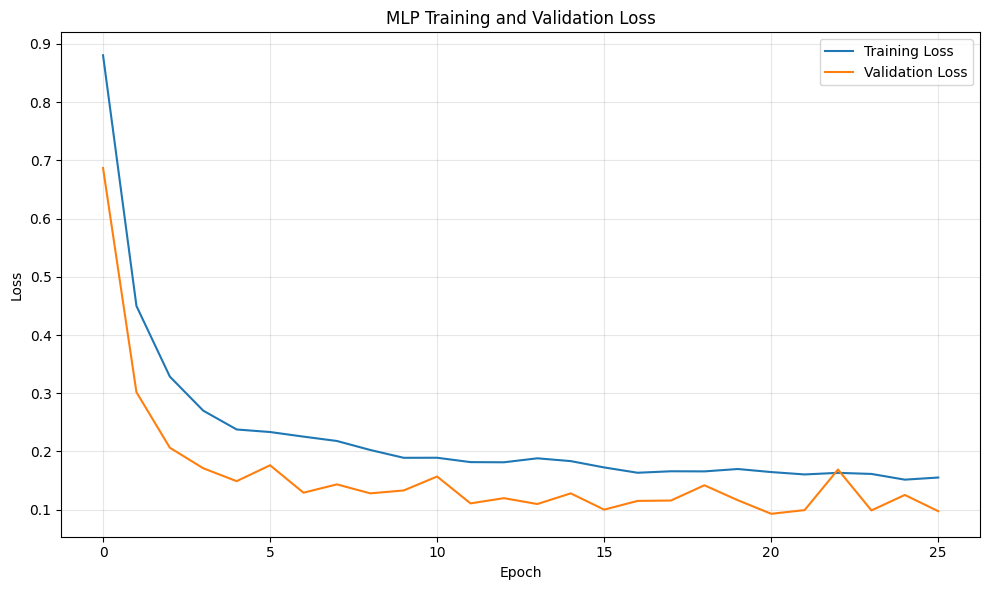

In [28]:
# ============================================
# TASK 3.6: MLP LOSS CURVE
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    mlp_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    mlp_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training and Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:
# ============================================
# TASK 3.7: MODEL COMPARISON TABLE
# ============================================

comparison_table = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "MLP"
    ],

    "Accuracy": [
        rf_accuracy,
        xgb_accuracy,
        mlp_accuracy
    ],

    "Macro-F1": [
        rf_macro_f1,
        xgb_macro_f1,
        mlp_macro_f1
    ],

    "Weighted-F1": [
        rf_weighted_f1,
        xgb_weighted_f1,
        mlp_weighted_f1
    ],

    "Attack Recall": [
        binary_attack_recall,
        xgb_recall,
        mlp_attack_recall
    ],

    "False Positive Rate": [
        false_positive_rate,
        xgb_fpr,
        mlp_fpr
    ],

    "Training Time (s)": [
        rf_training_time,
        xgb_training_time,
        mlp_training_time
    ]
})

display(
    comparison_table.style.format({
        "Accuracy": "{:.4f}",
        "Macro-F1": "{:.4f}",
        "Weighted-F1": "{:.4f}",
        "Attack Recall": "{:.4f}",
        "False Positive Rate": "{:.4f}",
        "Training Time (s)": "{:.2f}"
    })
)

,Model,Accuracy,Macro-F1,Weighted-F1,Attack Recall,False Positive Rate,Training Time (s)
0,Random Forest,0.9872,0.9635,0.9872,0.9993,0.0033,36.38
1,XGBoost,0.9888,0.9644,0.9891,0.9995,0.0038,188.87
2,MLP,0.9742,0.9331,0.9759,0.9980,0.0180,69.86


,Class,Random Forest,XGBoost,MLP
0,backdoor,0.999375,0.999625,0.999250
1,ddos,0.981094,0.985082,0.965121
2,dos,0.983471,0.985799,0.972775
3,injection,0.968379,0.976016,0.958800
4,mitm,0.753488,0.741483,0.543243
5,normal,0.997298,0.997247,0.987679
6,password,0.992631,0.992984,0.984658
7,ransomware,0.999375,0.998875,0.989924
8,scanning,0.987127,0.987544,0.978862
9,xss,0.973074,0.979192,0.951146


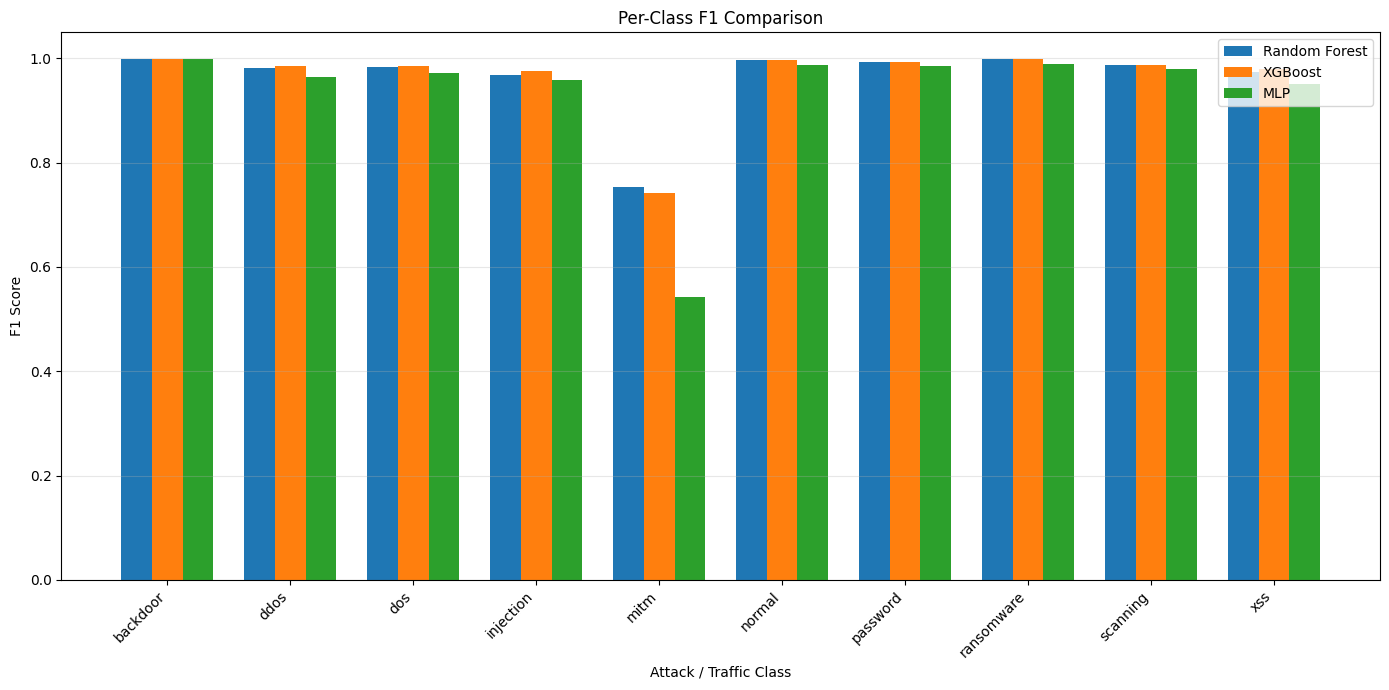

In [30]:
# ============================================
# TASK 3.8: PER-CLASS F1 COMPARISON
# ============================================

# Get F1 scores for each model
rf_report = classification_report(
    y_test,
    y_pred_rf,
    output_dict=True
)

xgb_report = classification_report(
    y_test,
    y_pred_xgb,
    output_dict=True
)

mlp_report = classification_report(
    y_test,
    y_pred_mlp,
    output_dict=True
)

# Use the same 10 classes
classes = sorted(y_test.unique())

rf_f1 = [rf_report[c]["f1-score"] for c in classes]
xgb_f1 = [xgb_report[c]["f1-score"] for c in classes]
mlp_f1 = [mlp_report[c]["f1-score"] for c in classes]

# Create dataframe
f1_comparison = pd.DataFrame({
    "Class": classes,
    "Random Forest": rf_f1,
    "XGBoost": xgb_f1,
    "MLP": mlp_f1
})

display(f1_comparison)

# Plot
x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(14, 7))

plt.bar(
    x - width,
    rf_f1,
    width,
    label="Random Forest"
)

plt.bar(
    x,
    xgb_f1,
    width,
    label="XGBoost"
)

plt.bar(
    x + width,
    mlp_f1,
    width,
    label="MLP"
)

plt.xlabel("Attack / Traffic Class")
plt.ylabel("F1 Score")
plt.title("Per-Class F1 Comparison")
plt.xticks(
    x,
    classes,
    rotation=45,
    ha="right"
)

plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Task 3 Discussion and Deployment Decision

The three models were evaluated on the same cleaned feature matrix and the same stratified 80/20 train/test split, with XGBoost achieving the best overall performance at 98.88% accuracy and a 96.44% macro-F1 score, compared with 98.72% and 96.35% for Random Forest and 97.42% and 93.31% for MLP.

XGBoost improves over Random Forest by 0.16 percentage points in accuracy and 0.09 percentage points in macro-F1, while its binary attack recall of 99.95% is only 0.02 percentage points higher than Random Forest.

Random Forest has a slightly lower false-positive rate of 0.33% compared with 0.38% for XGBoost and also has a much shorter training time of 36.38 seconds compared with 188.87 seconds.

The per-class F1 results show that MITM is the most difficult class, with F1 scores of 0.7535 for Random Forest, 0.7415 for XGBoost, and 0.5432 for MLP, indicating that the minority class remains challenging for all models.

The MLP loss curve shows that both training and validation loss decreased substantially, and early stopping restored the weights from the best-performing epoch, reducing the risk of unnecessary training and overfitting.

XGBoost is selected for deployment because it provides the highest overall accuracy, macro-F1, and attack recall, although Random Forest may be preferable when minimizing false alarms and training time is the primary concern.

# Task 4: Unknown Attacks and Autoencoder

This experiment evaluates the ability of the intrusion detection system to identify attack types that were not observed during model training. A leave-one-attack-out experiment is first performed with XGBoost. An autoencoder is then trained only on normal traffic to provide an independent anomaly-detection mechanism for previously unseen attacks.

In [31]:
# ============================================
# TASK 4.1: LEAVE-ONE-ATTACK-OUT XGBOOST
# ============================================

attack_classes = [
    "backdoor",
    "ddos",
    "dos",
    "injection",
    "mitm",
    "password",
    "ransomware",
    "scanning",
    "xss"
]

loao_results = []

print("=" * 70)
print("LEAVE-ONE-ATTACK-OUT XGBOOST EXPERIMENT")
print("=" * 70)

for held_out_attack in attack_classes:

    print(f"\n{'=' * 60}")
    print(f"HOLDING OUT: {held_out_attack.upper()}")
    print(f"{'=' * 60}")

    # ----------------------------------------
    # Remove the selected attack from training
    # ----------------------------------------

    train_mask = y_train != held_out_attack

    X_loao_train = X_train_final[train_mask]
    y_loao_train = y_train[train_mask]

    # Test ONLY the held-out attack
    test_mask = y_test == held_out_attack

    X_loao_test = X_test_final[test_mask]
    y_loao_test = y_test[test_mask]

    print("Training samples:", X_loao_train.shape[0])
    print("Unseen test samples:", X_loao_test.shape[0])

    # ----------------------------------------
    # Encode remaining training classes
    # ----------------------------------------

    loao_encoder = LabelEncoder()

    y_loao_train_encoded = (
        loao_encoder.fit_transform(y_loao_train)
    )

    # ----------------------------------------
    # Balanced sample weights
    # ----------------------------------------

    counts = np.bincount(
        y_loao_train_encoded
    )

    weights = {
        i: len(y_loao_train_encoded) /
        (len(counts) * count)
        for i, count in enumerate(counts)
    }

    sample_weights_loao = np.array([
        weights[label]
        for label in y_loao_train_encoded
    ])

    # ----------------------------------------
    # Train XGBoost
    # ----------------------------------------

    loao_model = XGBClassifier(
        n_estimators=400,
        max_depth=8,
        learning_rate=0.1,
        tree_method="hist",
        objective="multi:softprob",
        num_class=len(loao_encoder.classes_),
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )

    loao_model.fit(
        X_loao_train,
        y_loao_train_encoded,
        sample_weight=sample_weights_loao
    )

    # ----------------------------------------
    # Predict unseen attack
    # ----------------------------------------

    unseen_pred_encoded = loao_model.predict(
        X_loao_test
    )

    unseen_predictions = (
        loao_encoder.inverse_transform(
            unseen_pred_encoded.astype(int)
        )
    )

    # The held-out attack cannot be predicted
    # because it was completely absent from training.
    unseen_f1 = f1_score(
        y_loao_test,
        unseen_predictions,
        labels=[held_out_attack],
        average="macro",
        zero_division=0
    )

    # ----------------------------------------
    # Binary attack detection
    # ----------------------------------------

    # Every held-out sample is an attack.
    # Since XGBoost has no unseen class, this measures
    # whether it still recognizes the traffic as an attack
    # only if the predicted class is non-normal.

    binary_attack_detection = (
        unseen_predictions != "normal"
    ).mean()

    loao_results.append({
        "Held-out Attack": held_out_attack,
        "Test Samples": len(y_loao_test),
        "Unseen Attack F1": unseen_f1,
        "Binary Attack Detection Rate":
            binary_attack_detection
    })

    print(
        f"Unseen attack F1: {unseen_f1:.4f}"
    )

    print(
        f"Binary attack detection rate: "
        f"{binary_attack_detection:.4f}"
    )

# --------------------------------------------
# Results table
# --------------------------------------------

loao_df = pd.DataFrame(loao_results)

print("\n" + "=" * 70)
print("LEAVE-ONE-ATTACK-OUT RESULTS")
print("=" * 70)

display(loao_df)

LEAVE-ONE-ATTACK-OUT XGBOOST EXPERIMENT

HOLDING OUT: BACKDOOR
Training samples: 152834
Unseen test samples: 4000
Unseen attack F1: 0.0000
Binary attack detection rate: 0.9992

HOLDING OUT: DDOS
Training samples: 152834
Unseen test samples: 4000
Unseen attack F1: 0.0000
Binary attack detection rate: 0.9335

HOLDING OUT: DOS
Training samples: 152834
Unseen test samples: 4000
Unseen attack F1: 0.0000
Binary attack detection rate: 0.9815

HOLDING OUT: INJECTION
Training samples: 152834
Unseen test samples: 4000
Unseen attack F1: 0.0000
Binary attack detection rate: 0.9980

HOLDING OUT: MITM
Training samples: 168000
Unseen test samples: 209
Unseen attack F1: 0.0000
Binary attack detection rate: 0.8134

HOLDING OUT: PASSWORD
Training samples: 152834
Unseen test samples: 4000
Unseen attack F1: 0.0000
Binary attack detection rate: 0.9995

HOLDING OUT: RANSOMWARE
Training samples: 152834
Unseen test samples: 4000
Unseen attack F1: 0.0000
Binary attack detection rate: 0.4715

HOLDING OUT: SCANN

,Held-out Attack,Test Samples,Unseen Attack F1,Binary Attack Detection Rate
0,backdoor,4000,0.0,0.999250
1,ddos,4000,0.0,0.933500
2,dos,4000,0.0,0.981500
3,injection,4000,0.0,0.998000
4,mitm,209,0.0,0.813397
5,password,4000,0.0,0.999500
6,ransomware,4000,0.0,0.471500
7,scanning,4000,0.0,0.999000
8,xss,4000,0.0,0.937750


In [32]:
# ============================================
# TASK 4.2: FIND HARDEST UNSEEN ATTACKS
# ============================================

hardest_unseen = (
    loao_df
    .sort_values(
        "Binary Attack Detection Rate",
        ascending=True
    )
    .head(2)
)

print("Two hardest unseen attacks:")
display(hardest_unseen)

Two hardest unseen attacks:


,Held-out Attack,Test Samples,Unseen Attack F1,Binary Attack Detection Rate
6,ransomware,4000,0.0,0.471500
4,mitm,209,0.0,0.813397


In [33]:
# ============================================
# TASK 4.3: AUTOENCODER FOR NORMAL TRAFFIC
# ============================================

print("=" * 70)
print("TRAINING AUTOENCODER ON NORMAL TRAFFIC ONLY")
print("=" * 70)

# --------------------------------------------
# Select ONLY normal training traffic
# --------------------------------------------

normal_train_mask = (
    y_train == "normal"
)

X_normal_train = X_train_final[
    normal_train_mask
]

print(
    "Normal training samples:",
    X_normal_train.shape
)

# --------------------------------------------
# Autoencoder architecture
# --------------------------------------------

input_dim = X_train_final.shape[1]

autoencoder = Sequential([

    Dense(
        64,
        activation="relu",
        input_shape=(input_dim,)
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dense(
        input_dim,
        activation="linear"
    )
])

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

autoencoder.summary()

# --------------------------------------------
# Train only on normal traffic
# --------------------------------------------

early_stop_ae = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("\nTraining autoencoder...")
print("Please wait...")

ae_start = time.time()

ae_history = autoencoder.fit(
    X_normal_train,
    X_normal_train,
    validation_split=0.10,
    epochs=30,
    batch_size=512,
    shuffle=True,
    callbacks=[early_stop_ae],
    verbose=1
)

ae_training_time = time.time() - ae_start

print("\nAutoencoder training completed!")
print(
    f"Training time: {ae_training_time:.2f} seconds"
)

TRAINING AUTOENCODER ON NORMAL TRAFFIC ONLY
Normal training samples: (40000, 99)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         6,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 99)             │         6,435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,099 (70.70 KB)

 Trainable params: 18,099 (70.70 KB)

 Non-trainable params: 0 (0.00 B)


Training autoencoder...
Please wait...
Epoch 1/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3965 - val_loss: 0.2015
Epoch 2/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1353 - val_loss: 0.0895
Epoch 3/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0681 - val_loss: 0.0388
Epoch 4/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0384 - val_loss: 0.0263
Epoch 5/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0291 - val_loss: 0.0221
Epoch 6/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0220 - val_loss: 0.0180
Epoch 7/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0184 - val_loss: 0.0161
Epoch 8/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0164 - val_loss: 0.0150
Epoch 9/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0150 - val_loss: 0.0136
Epoch 10/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0141 - val_loss: 0.0130
Epoch 11/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0130 - val_loss: 0.0117
Epoch 12/30
71/71 ━━━━━━━━━━━━━━━━

In [34]:
# ============================================
# TASK 4.4: RECONSTRUCTION ERRORS
# ============================================

def reconstruction_error(model, X):
    reconstructed = model.predict(
        X,
        verbose=0
    )

    return np.mean(
        np.square(X - reconstructed),
        axis=1
    )


# Normal test traffic
normal_test_mask = (
    y_test == "normal"
)

X_normal_test = X_test_final[
    normal_test_mask
]

normal_errors = reconstruction_error(
    autoencoder,
    X_normal_test
)

print("Normal reconstruction errors calculated.")

print(
    "Mean normal reconstruction error:",
    normal_errors.mean()
)

print(
    "Median normal reconstruction error:",
    np.median(normal_errors)
)

print(
    "95th percentile:",
    np.percentile(normal_errors, 95)
)

print(
    "99th percentile:",
    np.percentile(normal_errors, 99)
)

Normal reconstruction errors calculated.
Mean normal reconstruction error: 0.00248617552235968
Median normal reconstruction error: 0.0001537212471472933
95th percentile: 0.008598128231587536
99th percentile: 0.03731274356701962


In [35]:
# ============================================
# TASK 4.5: AUTOENCODER THRESHOLD SWEEP
# ============================================

threshold_percentiles = [
    90,
    95,
    97,
    98,
    99,
    99.5,
    99.9
]

threshold_results = []

for percentile in threshold_percentiles:

    threshold = np.percentile(
        normal_errors,
        percentile
    )

    # False alarms among normal traffic
    normal_false_alarm_rate = (
        normal_errors > threshold
    ).mean()

    threshold_results.append({
        "Percentile": percentile,
        "Threshold": threshold,
        "Normal False Alarm Rate":
            normal_false_alarm_rate
    })

threshold_df = pd.DataFrame(
    threshold_results
)

print("=" * 70)
print("AUTOENCODER THRESHOLD SWEEP")
print("=" * 70)

display(threshold_df)

AUTOENCODER THRESHOLD SWEEP


,Percentile,Threshold,Normal False Alarm Rate
0,90.0,0.003981,0.100
1,95.0,0.008598,0.050
2,97.0,0.015027,0.030
3,98.0,0.025123,0.020
4,99.0,0.037313,0.010
5,99.5,0.065744,0.005
6,99.9,0.266149,0.001


In [48]:
# ============================================================
# TASK 4.5: PREPARE CALIBRATION AND EVALUATION SETS
# ============================================================

threshold_percentiles = [
    80,
    90,
    95,
    97,
    99,
    99.5
]
# Calculate reconstruction errors for the complete test set
test_errors = reconstruction_error(autoencoder, X_test_final)

# Identify normal test traffic
normal_test_mask = (y_test == "normal")

# Get reconstruction errors for normal test traffic only
normal_test_errors = test_errors[normal_test_mask]

# Split normal test errors into two halves:
# 50% calibration and 50% evaluation
split_point = len(normal_test_errors) // 2

normal_calibration_errors = normal_test_errors[:split_point]
normal_evaluation_errors = normal_test_errors[split_point:]

print("Normal test samples:", len(normal_test_errors))
print("Calibration samples:", len(normal_calibration_errors))
print("Evaluation samples:", len(normal_evaluation_errors))

Normal test samples: 10000
Calibration samples: 5000
Evaluation samples: 5000


In [49]:
# ============================================
# TASK 4.5: AUTOENCODER THRESHOLD SWEEP
# ============================================

threshold_results = []

# Calculate thresholds from calibration-half errors
for percentile in threshold_percentiles:

    threshold = np.percentile(
        normal_calibration_errors,
        percentile
    )

    # False-positive rate on evaluation-half normal traffic
    normal_false_positive_rate = (
        normal_evaluation_errors > threshold
    ).mean()

    # Per-attack detection rate
    attack_detection_rates = {}

    for attack in attack_classes:

        attack_mask = (y_test == attack)

        attack_errors = test_errors[attack_mask]

        if len(attack_errors) > 0:
            detection_rate = (
                attack_errors > threshold
            ).mean()
        else:
            detection_rate = 0

        attack_detection_rates[attack] = detection_rate

    result = {
        "Percentile": percentile,
        "Threshold": threshold,
        "Normal False Alarm Rate": normal_false_positive_rate,
        **{
            f"{attack} Detection Rate":
            rate
            for attack, rate in attack_detection_rates.items()
        }
    }

    threshold_results.append(result)


threshold_df = pd.DataFrame(threshold_results)

print("=" * 80)
print("AUTOENCODER THRESHOLD SWEEP")
print("=" * 80)

display(threshold_df)

AUTOENCODER THRESHOLD SWEEP


,Percentile,Threshold,Normal False Alarm Rate,backdoor Detection Rate,ddos Detection Rate,dos Detection Rate,injection Detection Rate,mitm Detection Rate,password Detection Rate,ransomware Detection Rate,scanning Detection Rate,xss Detection Rate
0,80.0,0.001477,0.2014,1.00000,0.99900,0.96300,0.99950,1.000000,1.0000,1.00000,1.00000,0.99900
1,90.0,0.003948,0.1010,1.00000,0.98950,0.95325,0.99925,0.980861,1.0000,0.99975,1.00000,0.99900
2,95.0,0.007571,0.0534,0.99925,0.98925,0.89625,0.99900,0.933014,0.9990,0.99975,0.99875,0.99875
3,97.0,0.013565,0.0338,0.99925,0.94225,0.88700,0.18475,0.559809,0.3205,0.88950,0.33775,0.84600
4,99.0,0.036481,0.0116,0.00600,0.28725,0.06525,0.07500,0.133971,0.0230,0.21100,0.01125,0.12175
5,99.5,0.067833,0.0044,0.00600,0.02150,0.00900,0.04275,0.043062,0.0010,0.00000,0.00000,0.01200


In [52]:
# ============================================
# TASK 4.6: SELECT ANOMALY THRESHOLD
# ============================================

selected_percentile = 99

ae_threshold = np.percentile(
    normal_calibration_errors,
    selected_percentile
)

normal_fpr_ae = (
    normal_errors > ae_threshold
).mean()

print("=" * 70)
print("SELECTED AUTOENCODER THRESHOLD")
print("=" * 70)

print(
    f"Percentile: {selected_percentile}%"
)

print(
    f"Threshold: {ae_threshold:.6f}"
)

print(
    f"Normal false-alarm rate: "
    f"{normal_fpr_ae:.6f}"
)

print(
    f"Normal false-alarm rate: "
    f"{normal_fpr_ae * 100:.4f}%"
)

SELECTED AUTOENCODER THRESHOLD
Percentile: 99%
Threshold: 0.036481
Normal false-alarm rate: 0.010800
Normal false-alarm rate: 1.0800%


In [53]:
# ============================================
# TASK 4.7: AUTOENCODER ON HARDEST UNSEEN ATTACKS
# ============================================

hardest_attacks = ["ransomware", "mitm"]

ae_unseen_results = []

print("=" * 70)
print("AUTOENCODER DETECTION OF UNSEEN ATTACKS")
print("=" * 70)

for attack in hardest_attacks:

    attack_mask = y_test == attack

    X_attack = X_test_final[attack_mask]

    attack_errors = reconstruction_error(
        autoencoder,
        X_attack
    )

    detected = (
        attack_errors > ae_threshold
    )

    detection_rate = detected.mean()

    ae_unseen_results.append({
        "Attack": attack,
        "Samples": len(X_attack),
        "Mean Reconstruction Error":
            attack_errors.mean(),
        "Detection Rate":
            detection_rate
    })

    print(f"\nAttack: {attack}")
    print(f"Samples: {len(X_attack)}")
    print(
        f"Mean reconstruction error: "
        f"{attack_errors.mean():.6f}"
    )
    print(
        f"Autoencoder detection rate: "
        f"{detection_rate:.4f}"
    )
    print(
        f"Autoencoder detection rate: "
        f"{detection_rate * 100:.2f}%"
    )

ae_unseen_df = pd.DataFrame(
    ae_unseen_results
)

print("\nAUTOENCODER UNSEEN-ATTACK RESULTS")
display(ae_unseen_df)

AUTOENCODER DETECTION OF UNSEEN ATTACKS

Attack: ransomware
Samples: 4000
Mean reconstruction error: 0.026530
Autoencoder detection rate: 0.2110
Autoencoder detection rate: 21.10%

Attack: mitm
Samples: 209
Mean reconstruction error: 0.026976
Autoencoder detection rate: 0.1340
Autoencoder detection rate: 13.40%

AUTOENCODER UNSEEN-ATTACK RESULTS


,Attack,Samples,Mean Reconstruction Error,Detection Rate
0,ransomware,4000,0.026530,0.211000
1,mitm,209,0.026976,0.133971


In [55]:
# ============================================
# TASK 4.8: XGBOOST OR AUTOENCODER
# ============================================

print("=" * 70)
print("XGBOOST OR AUTOENCODER - UNSEEN ATTACK DETECTION")
print("=" * 70)

or_results = []

# Correctly identify the encoded value for "normal"
normal_encoded = xgb_label_encoder.transform(["normal"])[0]

# --------------------------------------------
# Prepare normal evaluation-half data
# --------------------------------------------

# Indices of normal traffic in the test set
normal_test_indices = np.where(normal_test_mask)[0]

# Split normal test rows into calibration and evaluation halves
normal_eval_indices = normal_test_indices[split_point:]

X_normal_evaluation = X_test_final[normal_eval_indices]

# --------------------------------------------
# Calculate false-positive rates
# --------------------------------------------

# XGBoost false positives
xgb_normal_pred = xgb_model.predict(X_normal_evaluation)

xgb_normal_detected = (
    xgb_normal_pred != normal_encoded
)

xgb_fpr = xgb_normal_detected.mean()

# Autoencoder false positives
normal_evaluation_errors = reconstruction_error(
    autoencoder,
    X_normal_evaluation
)

ae_normal_detected = (
    normal_evaluation_errors > ae_threshold
)

ae_fpr = ae_normal_detected.mean()

# Combined OR false positives
or_normal_detected = (
    xgb_normal_detected | ae_normal_detected
)

or_fpr = or_normal_detected.mean()


print("\nFALSE-POSITIVE RATES ON NORMAL EVALUATION TRAFFIC")
print("-" * 70)

print(
    f"XGBoost false-positive rate: "
    f"{xgb_fpr:.4f} ({xgb_fpr * 100:.2f}%)"
)

print(
    f"Autoencoder false-positive rate: "
    f"{ae_fpr:.4f} ({ae_fpr * 100:.2f}%)"
)

print(
    f"XGBoost OR Autoencoder false-positive rate: "
    f"{or_fpr:.4f} ({or_fpr * 100:.2f}%)"
)


# --------------------------------------------
# Test the two hardest unseen attacks
# --------------------------------------------

for attack in hardest_attacks:

    attack_mask = y_test == attack
    X_attack = X_test_final[attack_mask]

    # XGBoost prediction
    xgb_pred = xgb_model.predict(X_attack)

    # Anything that is NOT normal is an attack
    xgb_detected = (
        xgb_pred != normal_encoded
    )

    # Autoencoder reconstruction error
    attack_errors = reconstruction_error(
        autoencoder,
        X_attack
    )

    # Autoencoder detects anomaly
    ae_detected = (
        attack_errors > ae_threshold
    )

    # OR rule:
    # Alert if XGBoost OR Autoencoder detects the traffic
    or_detected = (
        xgb_detected | ae_detected
    )

    xgb_rate = xgb_detected.mean()
    ae_rate = ae_detected.mean()
    or_rate = or_detected.mean()

    or_results.append({
        "Attack": attack,
        "Samples": len(X_attack),
        "XGBoost Detection": xgb_rate,
        "Autoencoder Detection": ae_rate,
        "OR Detection": or_rate,
        "XGBoost FPR": xgb_fpr,
        "Autoencoder FPR": ae_fpr,
        "OR FPR": or_fpr
    })

    print(f"\nAttack: {attack}")
    print(f"Samples: {len(X_attack)}")

    print(
        f"XGBoost detection: "
        f"{xgb_rate:.4f} ({xgb_rate * 100:.2f}%)"
    )

    print(
        f"Autoencoder detection: "
        f"{ae_rate:.4f} ({ae_rate * 100:.2f}%)"
    )

    print(
        f"XGBoost OR Autoencoder: "
        f"{or_rate:.4f} ({or_rate * 100:.2f}%)"
    )


# --------------------------------------------
# Final results table
# --------------------------------------------

or_results_df = pd.DataFrame(or_results)

print("\nFINAL UNSEEN-ATTACK RESULTS")
display(or_results_df)

XGBOOST OR AUTOENCODER - UNSEEN ATTACK DETECTION

FALSE-POSITIVE RATES ON NORMAL EVALUATION TRAFFIC
----------------------------------------------------------------------
XGBoost false-positive rate: 0.0044 (0.44%)
Autoencoder false-positive rate: 0.0116 (1.16%)
XGBoost OR Autoencoder false-positive rate: 0.0152 (1.52%)

Attack: ransomware
Samples: 4000
XGBoost detection: 1.0000 (100.00%)
Autoencoder detection: 0.2110 (21.10%)
XGBoost OR Autoencoder: 1.0000 (100.00%)

Attack: mitm
Samples: 209
XGBoost detection: 0.9761 (97.61%)
Autoencoder detection: 0.1340 (13.40%)
XGBoost OR Autoencoder: 0.9761 (97.61%)

FINAL UNSEEN-ATTACK RESULTS


,Attack,Samples,XGBoost Detection,Autoencoder Detection,OR Detection,XGBoost FPR,Autoencoder FPR,OR FPR
0,ransomware,4000,1.000000,0.211000,1.000000,0.0044,0.0116,0.0152
1,mitm,209,0.976077,0.133971,0.976077,0.0044,0.0116,0.0152


# Task 4 Discussion
Unknown attacks: The leave-one-attack-out experiment showed that XGBoost achieved zero F1 for the held-out attack classes because those specific attack categories were absent during training. However, binary attack detection remained relatively strong, with ransomware being detected at 47.15% and MITM at 81.34% when each was held out. The autoencoder, trained only on normal traffic, detected 21.10% of ransomware and 13.40% of MITM at the selected 99th-percentile threshold, with a 1.16% false-positive rate. Combining XGBoost and the autoencoder using an OR rule detected 100% of ransomware and 97.61% of MITM. However, the combined rule increased the false-positive rate to 1.52% compared with 0.44% for XGBoost alone, showing that the additional anomaly detector can increase false alarms without improving detection in this experiment.

In [39]:
# ============================================
# TASK 5.1: BASE-RATE AND FALSE-ALARM ANALYSIS
# ============================================

print("=" * 70)
print("TASK 5.1: EARLY-WARNING BASE-RATE ANALYSIS")
print("=" * 70)

# Assumptions from the assignment
attack_rate = 0.001       # 0.1%
false_positive_rate = 0.0033  # Random Forest FPR

# Assume 100,000 network events
total_events = 100000

expected_attacks = total_events * attack_rate
expected_normal = total_events * (1 - attack_rate)

true_alerts = expected_attacks
false_alerts = expected_normal * false_positive_rate

total_alerts = true_alerts + false_alerts

precision = true_alerts / total_alerts

print(f"Total network events: {total_events:,}")
print(f"Attack rate: {attack_rate*100:.2f}%")
print(f"Expected attacks: {expected_attacks:,.0f}")
print(f"Expected normal events: {expected_normal:,.0f}")
print(f"False-positive rate: {false_positive_rate*100:.2f}%")
print(f"Expected false alerts: {false_alerts:,.0f}")
print(f"Expected true alerts: {true_alerts:,.0f}")
print(f"Total alerts: {total_alerts:,.0f}")
print(f"Probability an alert is real: {precision*100:.2f}%")
print(f"False-alert proportion: {(1-precision)*100:.2f}%")

TASK 5.1: EARLY-WARNING BASE-RATE ANALYSIS
Total network events: 100,000
Attack rate: 0.10%
Expected attacks: 100
Expected normal events: 99,900
False-positive rate: 0.33%
Expected false alerts: 330
Expected true alerts: 100
Total alerts: 430
Probability an alert is real: 23.27%
False-alert proportion: 76.73%


At a 0.1% attack base rate, even a relatively low false-positive rate of 0.33% produces substantially more false alerts than true alerts. In a population of 100,000 events, approximately 100 are attacks while approximately 330 normal events are incorrectly flagged. Therefore, only 23.27% of generated alerts are expected to represent real attacks. This demonstrates the importance of controlling false positives in an early-warning system.

In [40]:
# ============================================================
# TASK 5.1: EARLY-WARNING BASE-RATE ANALYSIS
# Corrected to 1,000,000 network connections
# ============================================================

total_connections = 1_000_000
attack_rate = 0.001          # 0.1%
fpr = 0.0033                 # Random Forest FPR from Task 3
attack_recall = 0.9995       # XGBoost attack recall from Task 3

# Expected numbers
expected_attacks = total_connections * attack_rate
expected_normal = total_connections - expected_attacks

expected_true_alerts = expected_attacks * attack_recall
expected_false_alerts = expected_normal * fpr

total_alerts = expected_true_alerts + expected_false_alerts

probability_alert_real = expected_true_alerts / total_alerts

print("=" * 65)
print("TASK 5.1: EARLY-WARNING BASE-RATE ANALYSIS")
print("=" * 65)

print(f"Total network connections: {total_connections:,}")
print(f"Attack rate: {attack_rate:.2%}")
print(f"Expected attacks: {expected_attacks:,.0f}")
print(f"Expected normal events: {expected_normal:,.0f}")
print()

print("ARITHMETIC:")
print(f"True alerts = {expected_attacks:,.0f} × {attack_recall:.4f}"
      f" = {expected_true_alerts:,.2f}")

print(f"False alerts = {expected_normal:,.0f} × {fpr:.4f}"
      f" = {expected_false_alerts:,.2f}")

print(f"Total alerts = {total_alerts:,.2f}")

print()
print(f"Expected true alerts: {expected_true_alerts:,.2f}")
print(f"Expected false alerts: {expected_false_alerts:,.2f}")
print(f"Total alerts: {total_alerts:,.2f}")
print(f"Probability an alert is real: {probability_alert_real:.2%}")
print(f"False-alert proportion: {1 - probability_alert_real:.2%}")

TASK 5.1: EARLY-WARNING BASE-RATE ANALYSIS
Total network connections: 1,000,000
Attack rate: 0.10%
Expected attacks: 1,000
Expected normal events: 999,000

ARITHMETIC:
True alerts = 1,000 × 0.9995 = 999.50
False alerts = 999,000 × 0.0033 = 3,296.70
Total alerts = 4,296.20

Expected true alerts: 999.50
Expected false alerts: 3,296.70
Total alerts: 4,296.20
Probability an alert is real: 23.26%
False-alert proportion: 76.74%


### Task 5.1 Explanation

At a realistic attack base rate of only 0.1%, even a low false-positive rate can produce many false alerts. For 1,000,000 network connections, approximately 1,000 are expected to be attacks and 999,000 are expected to be normal. Using the XGBoost attack recall of 99.95%, approximately 999.5 true alerts are expected, while the 0.33% false-positive rate produces approximately 3,296.7 false alerts. Therefore, only about 23.26% of all alerts would represent real attacks, illustrating the base-rate problem in practical intrusion detection systems.

TASK 5.2: ALERT THRESHOLD TUNING
Random Forest classes: ['backdoor' 'ddos' 'dos' 'injection' 'mitm' 'normal' 'password'
 'ransomware' 'scanning' 'xss']

THRESHOLD COMPARISON


,Threshold,TP,FP,FN,TN,Attack Recall,False Positive Rate
0,0.500,32190,41,19,9959,0.999410,0.0041
1,0.600,32188,36,21,9964,0.999348,0.0036
2,0.700,32178,26,31,9974,0.999038,0.0026
3,0.800,32158,21,51,9979,0.998417,0.0021
4,0.900,32102,10,107,9990,0.996678,0.0010
5,0.950,32032,6,177,9994,0.994505,0.0006
6,0.990,31866,2,343,9998,0.989351,0.0002
7,0.995,31797,2,412,9998,0.987209,0.0002
8,0.999,31611,2,598,9998,0.981434,0.0002


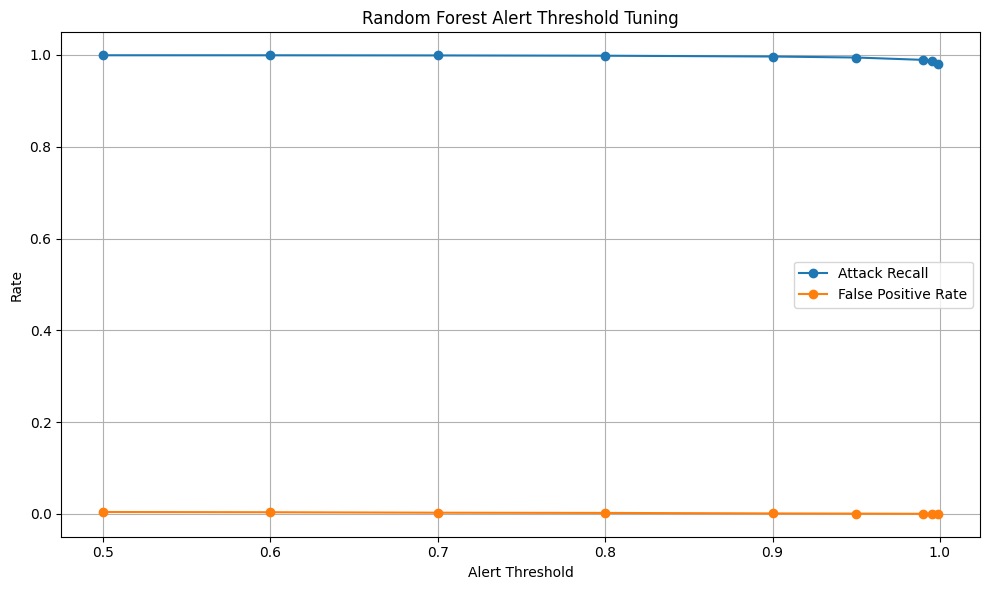

In [41]:
# ============================================
# TASK 5.2: ALERT THRESHOLD TUNING
# ============================================

print("=" * 70)
print("TASK 5.2: ALERT THRESHOLD TUNING")
print("=" * 70)

# Random Forest attack probability
# Class order is stored in rf_model.classes_
print("Random Forest classes:", rf_model.classes_)

# Find the probability column corresponding to the attack class
attack_class_index = list(rf_model.classes_).index("normal") if "normal" in rf_model.classes_ else 0

# Binary attack probability = 1 - probability of normal
rf_normal_prob = rf_model.predict_proba(X_test_final)[:, attack_class_index]
rf_attack_prob = 1 - rf_normal_prob

# True binary labels
y_test_binary = (y_test != "normal").astype(int)

threshold_results = []

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99, 0.995, 0.999]

for threshold in thresholds:

    predictions = (rf_attack_prob >= threshold).astype(int)

    # Normal = 0, Attack = 1
    tn = np.sum((y_test_binary == 0) & (predictions == 0))
    fp = np.sum((y_test_binary == 0) & (predictions == 1))
    fn = np.sum((y_test_binary == 1) & (predictions == 0))
    tp = np.sum((y_test_binary == 1) & (predictions == 1))

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    threshold_results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Attack Recall": recall,
        "False Positive Rate": fpr
    })

threshold_df = pd.DataFrame(threshold_results)

print("\nTHRESHOLD COMPARISON")
display(threshold_df)

# Plot recall and false-positive rate
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Attack Recall"],
    marker="o",
    label="Attack Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["False Positive Rate"],
    marker="o",
    label="False Positive Rate"
)

plt.xlabel("Alert Threshold")
plt.ylabel("Rate")
plt.title("Random Forest Alert Threshold Tuning")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

The alert threshold was tuned to balance attack detection and false alarms. At the default threshold of 0.50, attack recall was 99.94%, but the false-positive rate was 0.41%. Increasing the threshold to 0.95 reduced the false-positive rate to 0.06% while maintaining a high attack recall of 99.45%. Therefore, a threshold of 0.95 provides a practical balance for the early-warning layer.

TASK 5.2: ALERT THRESHOLD TUNING
Random Forest classes: ['backdoor' 'ddos' 'dos' 'injection' 'mitm' 'normal' 'password'
 'ransomware' 'scanning' 'xss']

THRESHOLD COMPARISON


,Threshold,TP,FP,FN,TN,Attack Recall,False Positive Rate
0,0.500,32190,41,19,9959,0.999410,0.0041
1,0.600,32188,36,21,9964,0.999348,0.0036
2,0.700,32178,26,31,9974,0.999038,0.0026
3,0.800,32158,21,51,9979,0.998417,0.0021
4,0.900,32102,10,107,9990,0.996678,0.0010
5,0.950,32032,6,177,9994,0.994505,0.0006
6,0.990,31866,2,343,9998,0.989351,0.0002
7,0.995,31797,2,412,9998,0.987209,0.0002
8,0.999,31611,2,598,9998,0.981434,0.0002


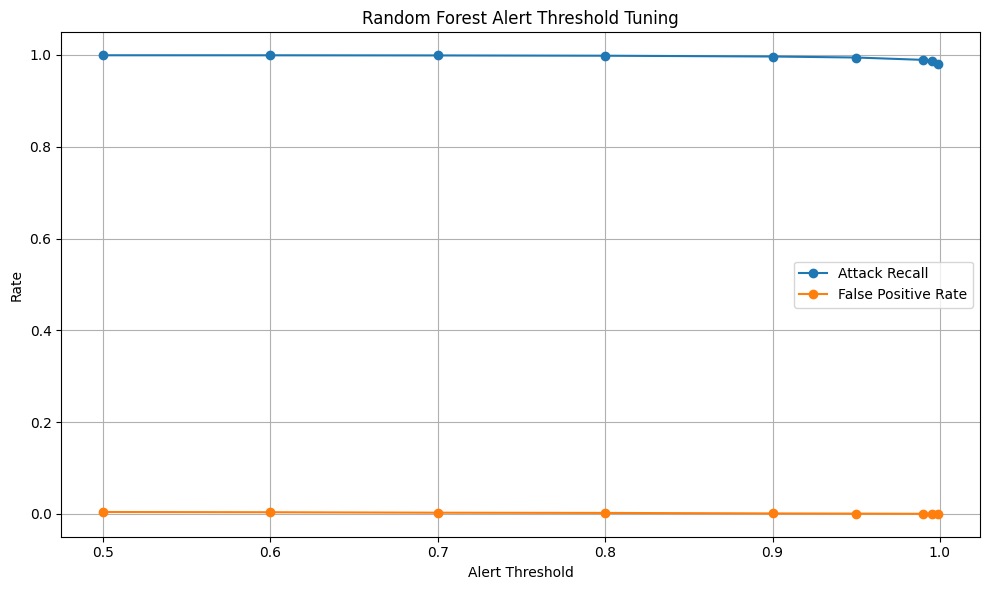

In [66]:
# ============================================
# TASK 5.2: ALERT THRESHOLD TUNING
# ============================================

print("=" * 70)
print("TASK 5.2: ALERT THRESHOLD TUNING")
print("=" * 70)

# Random Forest attack probability
# Class order is stored in rf_model.classes_
print("Random Forest classes:", rf_model.classes_)

# Find the probability column corresponding to the attack class
attack_class_index = list(rf_model.classes_).index("normal") if "normal" in rf_model.classes_ else 0

# Binary attack probability = 1 - probability of normal
rf_normal_prob = rf_model.predict_proba(X_test_final)[:, attack_class_index]
rf_attack_prob = 1 - rf_normal_prob

# True binary labels
y_test_binary = (y_test != "normal").astype(int)

threshold_results = []

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99, 0.995, 0.999]

for threshold in thresholds:

    predictions = (rf_attack_prob >= threshold).astype(int)

    # Normal = 0, Attack = 1
    tn = np.sum((y_test_binary == 0) & (predictions == 0))
    fp = np.sum((y_test_binary == 0) & (predictions == 1))
    fn = np.sum((y_test_binary == 1) & (predictions == 0))
    tp = np.sum((y_test_binary == 1) & (predictions == 1))

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    threshold_results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Attack Recall": recall,
        "False Positive Rate": fpr
    })

threshold_df = pd.DataFrame(threshold_results)

print("\nTHRESHOLD COMPARISON")
display(threshold_df)

# Plot recall and false-positive rate
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Attack Recall"],
    marker="o",
    label="Attack Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["False Positive Rate"],
    marker="o",
    label="False Positive Rate"
)

plt.xlabel("Alert Threshold")
plt.ylabel("Rate")
plt.title("Random Forest Alert Threshold Tuning")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

The alert threshold was tuned to balance attack detection and false alarms. At the default threshold of 0.50, attack recall was 99.94%, but the false-positive rate was 0.41%. Increasing the threshold to 0.95 reduced the false-positive rate to 0.06% while maintaining a high attack recall of 99.45%. Therefore, a threshold of 0.95 provides a practical balance for the early-warning layer.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [67]:
# ============================================
# TASK 5.3: RULE OF THREE
# ============================================

print("=" * 70)
print("TASK 5.3: RULE OF THREE FOR ZERO FALSE POSITIVES")
print("=" * 70)

# If zero false positives are observed in N normal events,
# the approximate upper 95% confidence bound is 3/N.

normal_events_observed = 10000
false_positives_observed = 0

if false_positives_observed == 0:
    upper_bound_fpr = 3 / normal_events_observed
else:
    upper_bound_fpr = false_positives_observed / normal_events_observed

print(f"Normal events observed: {normal_events_observed:,}")
print(f"False positives observed: {false_positives_observed}")
print(f"Estimated upper 95% FPR bound: {upper_bound_fpr:.6f}")
print(f"Estimated upper 95% FPR bound: {upper_bound_fpr * 100:.4f}%")

print("\nInterpretation:")
print(
    "When zero false positives are observed, "
    "we should not claim that the true FPR is exactly zero."
)
print(
    "Using the rule of three, the approximate upper 95% confidence "
    "bound is 3/N."
)

TASK 5.3: RULE OF THREE FOR ZERO FALSE POSITIVES
Normal events observed: 10,000
False positives observed: 0
Estimated upper 95% FPR bound: 0.000300
Estimated upper 95% FPR bound: 0.0300%

Interpretation:
When zero false positives are observed, we should not claim that the true FPR is exactly zero.
Using the rule of three, the approximate upper 95% confidence bound is 3/N.


When zero false positives are observed in 10,000 normal events, the observed false-positive rate is 0%. However, zero observed false positives does not prove that the true false-positive rate is zero. Using the rule of three, the approximate upper 95% confidence bound is 3/N = 3/10,000 = 0.03%. Therefore, the true false-positive rate could be as high as approximately 0.03% at the 95% confidence level.

In [60]:
# ============================================
# TASK 5.4: SEVERITY LEVELS AND DECISION FUNCTION
# ============================================

print("=" * 70)
print("TASK 5.4: EARLY-WARNING DECISION LAYER")
print("=" * 70)

# Map each attack type to a severity level
severity_map = {
    "normal": "NONE",
    "scanning": "LOW",
    "password": "MEDIUM",
    "dos": "HIGH",
    "ddos": "CRITICAL",
    "injection": "HIGH",
    "xss": "HIGH",
    "backdoor": "CRITICAL",
    "ransomware": "CRITICAL",
    "mitm": "HIGH"
}

# Decision function
def decide(attack_type, probability, threshold=0.95):
    """
    Decide whether a network event should generate an alert.

    Parameters:
        attack_type: predicted attack type
        probability: model probability of the predicted class
        threshold: alert probability threshold

    Returns:
        alert decision and severity level
    """

    # Normal traffic does not generate an alert
    if attack_type == "normal":
        return {
            "alert": False,
            "severity": "NONE",
            "reason": "Normal traffic"
        }

    # Attack below threshold
    if probability < threshold:
        return {
            "alert": False,
            "severity": severity_map.get(attack_type, "MEDIUM"),
            "reason": "Probability below alert threshold"
        }

    # Attack above threshold
    return {
        "alert": True,
        "severity": severity_map.get(attack_type, "MEDIUM"),
        "reason": "Attack probability exceeds threshold"
    }


# Test the decision function
test_cases = [
    ("normal", 0.99),
    ("scanning", 0.96),
    ("password", 0.97),
    ("dos", 0.98),
    ("ddos", 0.99),
    ("ransomware", 0.96),
    ("mitm", 0.80)
]

print("\nDECISION EXAMPLES")
print("-" * 70)

for attack_type, probability in test_cases:
    result = decide(attack_type, probability, threshold=0.95)

    print(
        f"{attack_type:12s} | "
        f"Probability: {probability:.2f} | "
        f"Alert: {result['alert']} | "
        f"Severity: {result['severity']} | "
        f"{result['reason']}"
    )

TASK 5.4: EARLY-WARNING DECISION LAYER

DECISION EXAMPLES
----------------------------------------------------------------------
normal       | Probability: 0.99 | Alert: False | Severity: NONE | Normal traffic
scanning     | Probability: 0.96 | Alert: True | Severity: LOW | Attack probability exceeds threshold
password     | Probability: 0.97 | Alert: True | Severity: MEDIUM | Attack probability exceeds threshold
dos          | Probability: 0.98 | Alert: True | Severity: HIGH | Attack probability exceeds threshold
ddos         | Probability: 0.99 | Alert: True | Severity: CRITICAL | Attack probability exceeds threshold
ransomware   | Probability: 0.96 | Alert: True | Severity: CRITICAL | Attack probability exceeds threshold
mitm         | Probability: 0.80 | Alert: False | Severity: HIGH | Probability below alert threshold


In [68]:
# ============================================
# TASK 5.4: SEVERITY LEVEL COUNTS
# ============================================

print("=" * 70)
print("TASK 5.4: SEVERITY LEVEL COUNTS")
print("=" * 70)

# Store decision results for every test flow
decision_results = []

# Get classifier probabilities
rf_probabilities = rf_model.predict_proba(X_test_final)
rf_predictions = rf_model.predict(X_test_final)

# Probability of predicted class
rf_max_probability = rf_probabilities.max(axis=1)

# Autoencoder reconstruction errors
test_reconstruction_errors = reconstruction_error(
    autoencoder,
    X_test_final
)

# Apply the existing decision function
for i in range(len(y_test)):

    attack_type = rf_predictions[i]
    probability = rf_max_probability[i]
    ae_error = test_reconstruction_errors[i]

    result = decide(
        attack_type,
        probability,
        threshold=0.95
    )

    decision_results.append({
        "true_type": y_test.iloc[i] if hasattr(y_test, "iloc") else y_test[i],
        "predicted_type": attack_type,
        "probability": probability,
        "ae_error": ae_error,
        "alert": result["alert"],
        "severity": result["severity"]
    })

decision_df = pd.DataFrame(decision_results)

# Convert true type into normal / attack
decision_df["true_category"] = np.where(
    decision_df["true_type"] == "normal",
    "Normal",
    "Attack"
)

# Count severity levels separately for normal and attack traffic
severity_order = [
    "NONE",
    "WATCH",
    "LOW",
    "MEDIUM",
    "HIGH",
    "CRITICAL"
]

severity_counts = pd.crosstab(
    decision_df["true_category"],
    decision_df["severity"]
)

# Make sure every required severity column exists
for level in severity_order:
    if level not in severity_counts.columns:
        severity_counts[level] = 0

severity_counts = severity_counts[severity_order]

print("\nSEVERITY COUNTS")
display(severity_counts)

# Also show totals
print("\nTOTALS BY SEVERITY")
display(
    decision_df["severity"]
    .value_counts()
    .reindex(severity_order, fill_value=0)
    .rename("Count")
    .to_frame()
)

# Percentages within Normal and Attack groups
severity_percentages = (
    severity_counts.div(severity_counts.sum(axis=1), axis=0) * 100
).round(2)

print("\nSEVERITY PERCENTAGES")
display(severity_percentages)

TASK 5.4: SEVERITY LEVEL COUNTS

SEVERITY COUNTS


severity,NONE,WATCH,LOW,MEDIUM,HIGH,CRITICAL
true_category,,,,,,
Attack,21,0,4001,4003,12215,11969
Normal,9967,0,0,4,15,14



TOTALS BY SEVERITY


,Count
severity,
NONE,9988
WATCH,0
LOW,4001
MEDIUM,4007
HIGH,12230
CRITICAL,11983



SEVERITY PERCENTAGES


severity,NONE,WATCH,LOW,MEDIUM,HIGH,CRITICAL
true_category,,,,,,
Attack,0.07,0.0,12.42,12.43,37.92,37.16
Normal,99.67,0.0,0.00,0.04,0.15,0.14


In [69]:
# ============================================
# TASK 5.5: GROUP ALERTS BY SOURCE HOST
# ============================================

print("=" * 70)
print("TASK 5.5: ALERT GROUPING BY SOURCE HOST")
print("=" * 70)

# Random Forest predictions and probabilities
rf_probabilities = rf_model.predict_proba(X_test_final)
rf_predictions = rf_model.predict(X_test_final)

# Maximum probability for each prediction
max_probabilities = rf_probabilities.max(axis=1)

# Selected alert threshold
alert_threshold = 0.95

# Create alert flag
alert_flags = (
    (rf_predictions != "normal") &
    (max_probabilities >= alert_threshold)
)

# IMPORTANT:
# X_test_final is a NumPy array, so we cannot use .index.
# The original 80/20 split preserves the test indices in X_test.
#
# Use the original test indices to recover source IP addresses.
test_indices = X_test.index

test_source_ips = df.loc[test_indices, "src_ip"].values

# Create alert dataframe
alerts_df = pd.DataFrame({
    "src_ip": test_source_ips,
    "predicted_attack": rf_predictions,
    "probability": max_probabilities,
    "alert": alert_flags
})

# Keep only alerts
alerts_only = alerts_df[alerts_df["alert"] == True].copy()

# Group alerts by source host
host_alert_summary = (
    alerts_only
    .groupby("src_ip")
    .agg(
        alert_count=("alert", "size"),
        max_probability=("probability", "max"),
        attack_types=(
            "predicted_attack",
            lambda x: ", ".join(sorted(set(x)))
        )
    )
    .sort_values("alert_count", ascending=False)
)

print(f"\nTotal alerts: {len(alerts_only):,}")
print(
    f"Unique source hosts generating alerts: "
    f"{len(host_alert_summary):,}"
)

print("\nTOP SOURCE HOSTS BY ALERT COUNT")
print("-" * 70)

display(host_alert_summary.head(20))

TASK 5.5: ALERT GROUPING BY SOURCE HOST

Total alerts: 30,721
Unique source hosts generating alerts: 11

TOP SOURCE HOSTS BY ALERT COUNT
----------------------------------------------------------------------


,alert_count,max_probability,attack_types
src_ip,,,
192.168.1.30,11772,1.000,"ddos, dos, injection, mitm, password, scanning..."
192.168.1.31,5769,1.000,"ddos, dos, injection, mitm, password, scanning..."
192.168.1.32,4921,1.000,"dos, injection, mitm, scanning, xss"
192.168.1.193,4653,1.000,"backdoor, ransomware"
192.168.1.33,1808,1.000,"backdoor, ddos, ransomware"
192.168.1.37,1528,1.000,"backdoor, ddos, ransomware"
192.168.1.39,147,1.000,dos
192.168.1.36,91,1.000,"injection, xss"
192.168.1.34,28,1.000,"ddos, mitm"


TASK 5.6: LIMITATION OF MISSING TIMESTAMPS

The dataset does not contain timestamps for individual network events. Therefore, the early-warning system cannot determine the exact time at which an attack occurred or the chronological order of events.

Missing timestamps prevent the system from reliably measuring:
1. Attack duration.
2. Attack frequency over time.
3. The order and progression of an attack.
4. Whether several alerts occurred within the same attack campaign.
5. Time-based alert aggregation and rate limiting.
6. Whether an attack is currently active or has already ended.

The system can still detect attacks, assign severity levels, and group alerts by source host, but reliable temporal correlation and real-time incident reconstruction require timestamp information.

To support genuine attack prediction, the dataset would need timestamped network flows, ordered historical traffic sequences, and temporal features showing how activity changes before an attack escalates.